# 07 — Explainability (Grad-CAM / Grad-CAM++)
Target layer `features[-1]` (1×1 head conv, 12×12 @ 384px). Deletion/Insertion AUC on the **full test fold**, vs. random and center-Gaussian baselines, paired tests, parameter-randomization sanity check, and correct / misclassified cases (BACTERIA→VIRUS and VIRUS→BACTERIA).

In [1]:
import sys, json, time, copy, warnings
from pathlib import Path
import numpy as np, pandas as pd, torch
import torch.nn.functional as F
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import wilcoxon
from torch.utils.data import DataLoader, Subset
from torchvision.transforms.v2.functional import gaussian_blur
warnings.filterwarnings("ignore")
sns.set_theme(style="white", context="notebook")

PROJECT_ROOT = Path("/mnt/g/Research paper/Research paper/Pneumonia-MultiModel-XAI")
SPLITS_DIR = PROJECT_ROOT / "splits"
CACHE_DIR  = Path.home() / "cache_384"
RES = PROJECT_ROOT / "results"
SRC_DIR = PROJECT_ROOT / "src"
XAI_DIR = RES / "xai"; XAI_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = RES / "figures"; FIG_DIR.mkdir(exist_ok=True)
sys.path.insert(0, str(SRC_DIR))

FOLD, SEED = 0, 42
STEPS = 10            # deletion/insertion steps
N_EVAL = None        # stratified random subset of the test fold for Deletion/Insertion (None = all)
N_SANITY = 150        # images for the randomization test
BATCH, WORKERS = 16, 2
MODEL_SPECS = {"EffNetV2-S": "baseline:efficientnet_v2_s", "EffNetV2-S + ECA": "proposed:efficientnet_v2_s:eca"}
TARGET_LAYER = "features[-1]"
CLASSES = ["NORMAL", "BACTERIA", "VIRUS"]

from pneumo_data import CXRDataset, IMAGENET_MEAN, IMAGENET_STD
from pneumo_models import build_model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BLACK = (-torch.tensor(IMAGENET_MEAN) / torch.tensor(IMAGENET_STD)).view(1, 3, 1, 1).to(device)  # raw pixel 0 after normalization
print("Device:", device)

Device: cuda


In [2]:
# ============================================================
# Load fold-k test set + checkpoints
# ============================================================
ds = CXRDataset(SPLITS_DIR / f"fold{FOLD}_test.csv", CACHE_DIR, train=False)
loader = DataLoader(ds, batch_size=BATCH, shuffle=False, num_workers=WORKERS)
labels = np.array(ds.labels)
N = len(ds)

models = {}
for name, spec in MODEL_SPECS.items():
    m = build_model(spec, pretrained=False)
    m.load_state_dict(torch.load(RES / f"fold{FOLD}_seed{SEED}" / spec.replace(":", "_") / "best.pt", map_location="cpu"))
    models[name] = m.to(device).eval()
print("Test images:", N, "| models:", list(models))

Test images: 1171 | models: ['EffNetV2-S', 'EffNetV2-S + ECA']


In [3]:
# ============================================================
# Grad-CAM + Grad-CAM++ (own implementation, one backward pass gives both)
# ============================================================
def get_layer(model):
    return model.features[-1]

def cam_batch(model, x, target=None):
    store = {}
    layer = get_layer(model)
    def fwd(m, i, o):
        store["A"] = o
        o.register_hook(lambda g: store.__setitem__("G", g))
    h = layer.register_forward_hook(fwd)
    with torch.enable_grad():
        model.zero_grad(set_to_none=True)
        out = model(x)
        t = out.argmax(1) if target is None else target
        out.gather(1, t[:, None]).sum().backward()
    h.remove()
    A, G = store["A"].detach(), store["G"].detach()
    gc = F.relu((G.mean((2, 3), keepdim=True) * A).sum(1))                      # Grad-CAM
    g2, g3 = G ** 2, G ** 3
    den = 2 * g2 + A.sum((2, 3), keepdim=True) * g3
    alpha = g2 / torch.where(den != 0, den, torch.ones_like(den))
    gcpp = F.relu(((alpha * F.relu(G)).sum((2, 3), keepdim=True) * A).sum(1))   # Grad-CAM++
    return gc, gcpp, out.detach().softmax(1), t

CAMS = {}
for name, model in models.items():
    t0 = time.time()
    gcs, gpps, probs, preds = [], [], [], []
    for x, _ in loader:
        gc, gpp, p, t = cam_batch(model, x.to(device))
        gcs.append(gc.cpu()); gpps.append(gpp.cpu()); probs.append(p.cpu()); preds.append(t.cpu())
    CAMS[name] = dict(gradcam=torch.cat(gcs), gradcampp=torch.cat(gpps),
                      probs=torch.cat(probs).numpy(), pred=torch.cat(preds).numpy())
    acc = (CAMS[name]["pred"] == labels).mean()
    print(f"{name}: cams {tuple(CAMS[name]['gradcam'].shape)} | test acc {acc:.4f} | {time.time()-t0:.0f}s")

EffNetV2-S: cams (1171, 12, 12) | test acc 0.8471 | 201s
EffNetV2-S + ECA: cams (1171, 12, 12) | test acc 0.8480 | 262s


In [4]:
# ============================================================
# Saliency providers: Grad-CAM, Grad-CAM++, random (12x12 noise), center-Gaussian
# ============================================================
H = W = ds[0][0].shape[-1]
g = torch.Generator().manual_seed(0)
h_cam = CAMS[next(iter(CAMS))]["gradcam"].shape[-1]
RANDOM_CAM = torch.rand(N, h_cam, h_cam, generator=g)

def center_gaussian(h, w, sigma=0.4):
    ys, xs = torch.meshgrid(torch.linspace(-1, 1, h), torch.linspace(-1, 1, w), indexing="ij")
    return torch.exp(-(xs ** 2 + ys ** 2) / (2 * sigma ** 2))

CENTER = center_gaussian(H, W)

def up(cam, size=(H, W)):
    return F.interpolate(cam[:, None].float(), size=size, mode="bilinear", align_corners=False)[:, 0]

def saliency(name, kind, idx):
    if kind == "center":
        return CENTER.expand(len(idx), H, W).clone()
    src = {"gradcam": CAMS[name]["gradcam"], "gradcampp": CAMS[name]["gradcampp"], "random": RANDOM_CAM}[kind]
    return up(src[idx])

def norm01(m):
    mn, mx = m.amin((-2, -1), keepdim=True), m.amax((-2, -1), keepdim=True)
    return (m - mn) / (mx - mn + 1e-8)

def spearman_rows(a, b):
    a, b = a.flatten(1), b.flatten(1)
    ra, rb = a.argsort(1).argsort(1).float(), b.argsort(1).argsort(1).float()
    ra, rb = ra - ra.mean(1, keepdim=True), rb - rb.mean(1, keepdim=True)
    return (ra * rb).sum(1) / (ra.norm(dim=1) * rb.norm(dim=1) + 1e-8)

# center bias of each method: Spearman with the center-Gaussian at 48x48
cb = []
cg48 = center_gaussian(48, 48)[None]
for name in models:
    for kind in ["gradcam", "gradcampp"]:
        r = spearman_rows(up(CAMS[name][kind], (48, 48)), cg48.expand(N, 48, 48))
        cb.append({"Model": name, "Method": kind, "rho with center-Gaussian": f"{r.mean():.3f} ± {r.std():.3f}"})
pd.DataFrame(cb)

,Model,Method,rho with center-Gaussian
0,EffNetV2-S,gradcam,0.598 ± 0.164
1,EffNetV2-S,gradcampp,0.487 ± 0.122
2,EffNetV2-S + ECA,gradcam,0.624 ± 0.152
3,EffNetV2-S + ECA,gradcampp,0.579 ± 0.116


In [10]:
# ============================================================
# Deletion / Insertion AUC on the FULL test fold
#   deletion : top-ranked pixels -> black   | insertion: blurred image + top-ranked pixels restored
#   curve    : softmax prob. of the originally predicted class (RISE; Petsiuk et al., 2018)
# ============================================================
NONFINITE = {"n": 0}

@torch.no_grad()
def _prob(model, inp, tgt):
    with torch.autocast(device_type=device.type, enabled=device.type == "cuda"):
        lg = model(inp).float()
    bad = ~torch.isfinite(lg).all(1)
    if bad.any():                                   # fp16 overflow -> recompute only those rows in fp32
        NONFINITE["n"] += int(bad.sum())
        lg[bad] = model(inp[bad]).float()
    return lg.softmax(1).gather(1, tgt[:, None])[:, 0]

@torch.no_grad()
def del_ins(model, x, tgt, sal, steps=STEPS):
    B, _, Hh, Ww = x.shape; n_pix = Hh * Ww
    s = sal.flatten(1) + 1e-6 * torch.rand(B, n_pix, device=x.device)       # break ties (ReLU zeros)
    order = s.argsort(1, descending=True)
    rank = torch.empty_like(order)
    rank.scatter_(1, order, torch.arange(n_pix, device=x.device).expand(B, n_pix))
    k = max(3, int(min(Hh, Ww) * 0.16) // 2 * 2 + 1)
    blur = gaussian_blur(x, kernel_size=[k, k], sigma=[k / 6, k / 6])
    pd_, pi_ = [], []
    for j in range(steps + 1):
        m = (rank < int(round(j / steps * n_pix))).view(B, 1, Hh, Ww).float()
        pd_.append(_prob(model, x * (1 - m) + BLACK * m, tgt))
        pi_.append(_prob(model, blur * (1 - m) + x * m, tgt))
    pd_, pi_ = torch.stack(pd_, 1), torch.stack(pi_, 1)
    auc = lambda p: ((p[:, :-1] + p[:, 1:]) / 2).sum(1) / steps
    return auc(pd_).cpu().numpy(), auc(pi_).cpu().numpy()

METHODS = ["gradcam", "gradcampp", "random", "center"]
AUC = {n: {k: {"del": [], "ins": []} for k in METHODS} for n in models}

rng_e = np.random.default_rng(0)
if N_EVAL is None or N_EVAL >= N:
    eval_idx = np.arange(N)
else:
    eval_idx = np.sort(np.concatenate([
        rng_e.choice(v, size=min(len(v), max(1, round(N_EVAL * len(v) / N))), replace=False)
        for v in (np.where(labels == c)[0] for c in range(3))]))
eval_loader = DataLoader(Subset(ds, eval_idx.tolist()), batch_size=BATCH, shuffle=False, num_workers=WORKERS)
n_batches = len(eval_loader)
print(f"Deletion/Insertion on {len(eval_idx)} images | steps {STEPS} | {n_batches} batches per model")

t0 = time.time()
for mi, (name, model) in enumerate(models.items()):
    pred_all = torch.tensor(CAMS[name]["pred"])
    i0 = 0
    for b, (x, _) in enumerate(eval_loader):
        idx = torch.tensor(eval_idx[i0:i0 + len(x)]); i0 += len(x)
        x = x.to(device); tgt = pred_all[idx].to(device)
        for kind in METHODS:
            d, i = del_ins(model, x, tgt, saliency(name, kind, idx).to(device))
            AUC[name][kind]["del"].append(d); AUC[name][kind]["ins"].append(i)
        if mi == 0 and b == 0:
            print(f"first batch {time.time()-t0:.1f}s -> estimated total ~{(time.time()-t0)*n_batches*len(models)/60:.1f} min", flush=True)
        elif (b + 1) % 5 == 0:
            print(f"  {name}: batch {b+1}/{n_batches} | {time.time()-t0:.0f}s | fp32 fallback rows so far: {NONFINITE['n']}", flush=True)
    print(f"{name} done | {time.time()-t0:.0f}s", flush=True)
    if device.type == "cuda": torch.cuda.empty_cache()

rows = []
for name in models:
    for kind in METHODS:
        d, i = np.concatenate(AUC[name][kind]["del"]), np.concatenate(AUC[name][kind]["ins"])
        AUC[name][kind] = {"del": d, "ins": i}
        rows.append({"Model": name, "Saliency": kind, "Deletion AUC (↓)": f"{d.mean():.3f} ± {d.std():.3f}",
                     "Insertion AUC (↑)": f"{i.mean():.3f} ± {i.std():.3f}", "Ins − Del (↑)": round(float((i - d).mean()), 3)})
auc_tab = pd.DataFrame(rows)
auc_tab.to_csv(XAI_DIR / "table_deletion_insertion.csv", index=False)
np.savez(XAI_DIR / "per_image_auc.npz", **{f"{n}|{k}|{m}": AUC[n][k][m] for n in models for k in METHODS for m in ("del", "ins")})
print("fp16 non-finite -> fp32 fallback rows:", NONFINITE["n"])
assert all(np.isfinite(AUC[n][k][m]).all() for n in models for k in METHODS for m in ("del", "ins")), "NaN still present"
auc_tab

Deletion/Insertion on 1171 images | steps 10 | 74 batches per model


first batch 65.7s -> estimated total ~162.1 min
  EffNetV2-S: batch 5/74 | 314s | fp32 fallback rows so far: 0
  EffNetV2-S: batch 10/74 | 625s | fp32 fallback rows so far: 0
  EffNetV2-S: batch 15/74 | 928s | fp32 fallback rows so far: 0
  EffNetV2-S: batch 20/74 | 1235s | fp32 fallback rows so far: 0
  EffNetV2-S: batch 25/74 | 1537s | fp32 fallback rows so far: 0
  EffNetV2-S: batch 30/74 | 1866s | fp32 fallback rows so far: 0
  EffNetV2-S: batch 35/74 | 2131s | fp32 fallback rows so far: 0
  EffNetV2-S: batch 40/74 | 2381s | fp32 fallback rows so far: 0
  EffNetV2-S: batch 45/74 | 2631s | fp32 fallback rows so far: 0
  EffNetV2-S: batch 50/74 | 2895s | fp32 fallback rows so far: 0
  EffNetV2-S: batch 55/74 | 3197s | fp32 fallback rows so far: 0
  EffNetV2-S: batch 60/74 | 3498s | fp32 fallback rows so far: 0
  EffNetV2-S: batch 65/74 | 3845s | fp32 fallback rows so far: 0
  EffNetV2-S: batch 70/74 | 4189s | fp32 fallback rows so far: 0
EffNetV2-S done | 4401s
  EffNetV2-S + ECA: ba

,Model,Saliency,Deletion AUC (↓),Insertion AUC (↑),Ins − Del (↑)
0,EffNetV2-S,gradcam,0.353 ± 0.202,0.785 ± 0.128,0.432
1,EffNetV2-S,gradcampp,0.336 ± 0.232,0.758 ± 0.158,0.422
2,EffNetV2-S,random,0.574 ± 0.212,0.472 ± 0.257,-0.102
3,EffNetV2-S,center,0.525 ± 0.223,0.748 ± 0.147,0.223
4,EffNetV2-S + ECA,gradcam,0.433 ± 0.124,0.721 ± 0.100,0.288
5,EffNetV2-S + ECA,gradcampp,0.441 ± 0.112,0.695 ± 0.128,0.254
6,EffNetV2-S + ECA,random,0.620 ± 0.147,0.526 ± 0.141,-0.094
7,EffNetV2-S + ECA,center,0.443 ± 0.143,0.684 ± 0.119,0.241


In [11]:
# ============================================================
# Paired tests (per-image AUCs, Wilcoxon signed-rank, n = all test images)
# ============================================================
names = list(models)
rows = []
def wil(a, b):
    d = a - b
    return 1.0 if np.allclose(d, 0) else wilcoxon(a, b).pvalue
for m_, lab in [("del", "Deletion"), ("ins", "Insertion")]:
    for kind in ["gradcam", "gradcampp"]:
        if len(names) == 2:
            a, b = AUC[names[1]][kind][m_], AUC[names[0]][kind][m_]
            rows.append({"Comparison": f"{names[1]} vs {names[0]} ({kind})", "Metric": lab,
                         "Δ mean": round(float((a - b).mean()), 4), "p (Wilcoxon)": f"{wil(a, b):.4g}"})
        for n in names:
            for ref in ["random", "center"]:
                a, b = AUC[n][kind][m_], AUC[n][ref][m_]
                rows.append({"Comparison": f"{n} {kind} vs {ref}", "Metric": lab,
                             "Δ mean": round(float((a - b).mean()), 4), "p (Wilcoxon)": f"{wil(a, b):.4g}"})
paired = pd.DataFrame(rows)
paired.to_csv(XAI_DIR / "table_paired_tests.csv", index=False)
paired

,Comparison,Metric,Δ mean,p (Wilcoxon)
0,EffNetV2-S + ECA vs EffNetV2-S (gradcam),Deletion,0.0796,0
1,EffNetV2-S gradcam vs random,Deletion,-0.2207,0
2,EffNetV2-S gradcam vs center,Deletion,-0.1722,0
3,EffNetV2-S + ECA gradcam vs random,Deletion,-0.1873,0
4,EffNetV2-S + ECA gradcam vs center,Deletion,-0.0104,0.0003652
5,EffNetV2-S + ECA vs EffNetV2-S (gradcampp),Deletion,0.1050,0
6,EffNetV2-S gradcampp vs random,Deletion,-0.2380,0
7,EffNetV2-S gradcampp vs center,Deletion,-0.1896,0
8,EffNetV2-S + ECA gradcampp vs random,Deletion,-0.1792,0
9,EffNetV2-S + ECA gradcampp vs center,Deletion,-0.0023,0.03606


In [ ]:
import gc; gc.collect(); torch.cuda.empty_cache()
print(torch.cuda.memory_allocated()/1e9, "GB allocated")

AcceleratorError: CUDA error: out of memory
Search for `cudaErrorMemoryAllocation' in https://docs.nvidia.com/cuda/cuda-runtime-api/group__CUDART__TYPES.html for more information.
For more detailed error information, run with CUDA_LOG_FILE=stderr


: 

In [12]:
# ============================================================
# Sanity check: cascading parameter randomization (Adebayo et al., 2018)
#   high Spearman rho with the original map after randomizing layers => explanation ignores the model
# ============================================================
def reinit(module):
    for m in module.modules():
        if hasattr(m, "reset_parameters"):
            m.reset_parameters()

def randomized(model, level):
    m = copy.deepcopy(model)
    parts = [m.classifier, m.features[-1], m.features[-2], m.features[-3]]
    if level == 4:
        reinit(m)
    else:
        for p in parts[: level + 1]:
            reinit(p)
    return m.to(device).eval()

LEVELS = ["classifier", "+ features[-1]", "+ features[-2]", "+ features[-3]", "all layers"]
rng = np.random.default_rng(0)
sidx = np.sort(rng.choice(N, size=min(N_SANITY, N), replace=False))
sub_loader = DataLoader(Subset(ds, sidx.tolist()), batch_size=BATCH, shuffle=False, num_workers=0)
xs = torch.cat([x for x, _ in sub_loader])

san_rows, san_raw = [], {}
for name, model in models.items():
    tgt = torch.tensor(CAMS[name]["pred"][sidx])
    for lv, lname in enumerate(LEVELS):
        torch.manual_seed(lv)
        rm = randomized(model, lv)
        res = {"gradcam": [], "gradcampp": []}
        for i in range(0, len(xs), BATCH):
            gc, gpp, _, _ = cam_batch(rm, xs[i:i + BATCH].to(device), tgt[i:i + BATCH].to(device))
            res["gradcam"].append(gc.cpu()); res["gradcampp"].append(gpp.cpu())
        for kind in res:
            new = torch.cat(res[kind])
            r = spearman_rows(up(CAMS[name][kind][sidx], (48, 48)), up(new, (48, 48)))
            san_rows.append({"Model": name, "Method": kind, "Randomized": lname, "rho_mean": r.mean().item(), "rho_sd": r.std().item()})
        del rm
san = pd.DataFrame(san_rows)
san.to_csv(XAI_DIR / "table_randomization_test.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, kind in zip(axes, ["gradcam", "gradcampp"]):
    for name in models:
        s = san[(san.Model == name) & (san.Method == kind)]
        ax.errorbar(range(len(LEVELS)), s["rho_mean"], yerr=s["rho_sd"], marker="o", capsize=3, label=name)
    ax.set_xticks(range(len(LEVELS))); ax.set_xticklabels(LEVELS, rotation=25, ha="right")
    ax.axhline(0, color="k", lw=0.6); ax.set_title(kind); ax.set_ylabel("Spearman ρ vs original map")
axes[0].legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "xai_randomization_test.png", dpi=300, bbox_inches="tight"); plt.show()
san.pivot_table(index=["Model", "Method"], columns="Randomized", values="rho_mean")[LEVELS].round(3)

[W1010 09:00:23.161491213 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 35651584 bytes (free: 0, total: 8589410304).
[W1010 09:00:41.629155038 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 14680064 bytes (free: 0, total: 8589410304).
[W1010 09:01:23.058301219 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 2097152 bytes (free: 0, total: 8589410304).
[W1010 09:01:35.196803763 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 14680064 bytes (free: 0, total: 8589410304).
[W1010 09:01:49.557624501 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 14680064 bytes (free: 0, total: 8589410304).
[W1010 09:01:57.750071086 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 14680064

OutOfMemoryError: CUDA out of memory. Tried to allocate 14.00 MiB. GPU 0 has a total capacity of 8.00 GiB of which 0 bytes is free. Including non-PyTorch memory, this process has 17179869184.00 GiB memory in use. Of the allocated memory 11.65 GiB is allocated by PyTorch, and 153.71 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

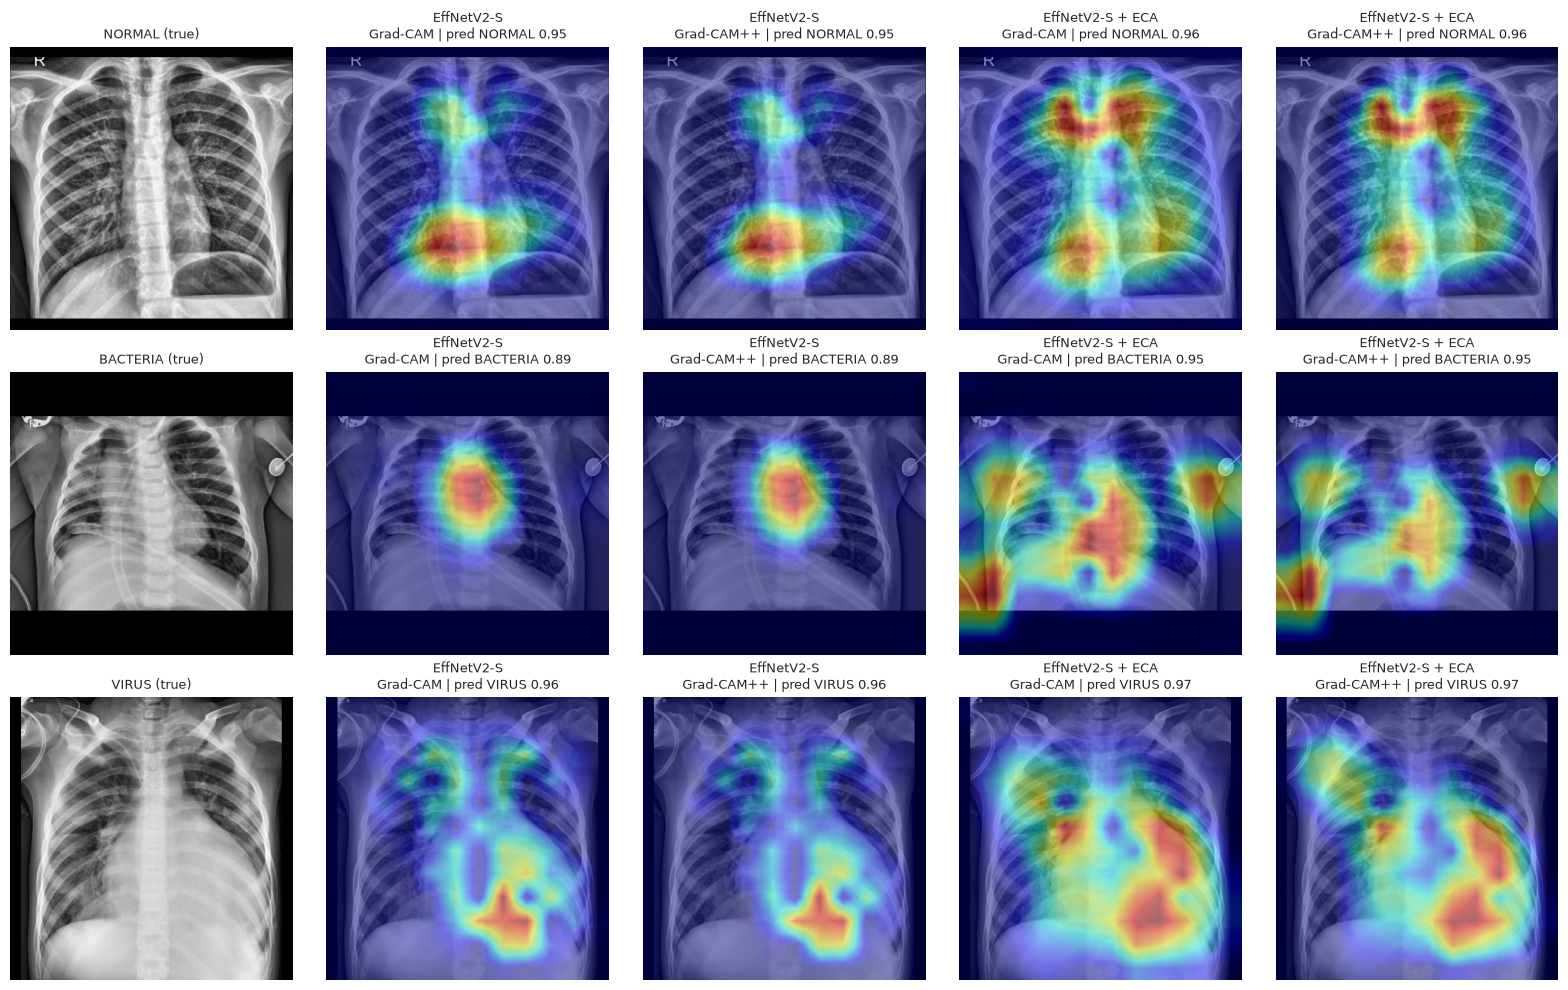

In [8]:
# ============================================================
# Qualitative: correctly classified (high confidence) per class
# ============================================================
def load_img(i):
    from PIL import Image
    return np.asarray(Image.open(ds.paths[i]).convert("L"))

def show(ax, i, cam, title):
    ax.imshow(load_img(i), cmap="gray")
    if cam is not None:
        ax.imshow(norm01(up(cam[None]))[0].numpy(), cmap="jet", alpha=0.45)
    ax.set_title(title, fontsize=9); ax.axis("off")

main = names[-1]
fig, axes = plt.subplots(3, 1 + 2 * len(names), figsize=(3.2 * (1 + 2 * len(names)), 10))
for r, c in enumerate(range(3)):
    ok = np.where((labels == c) & (CAMS[main]["pred"] == c))[0]
    if len(ok) == 0:
        ok = np.where(labels == c)[0]
    i = ok[np.argmax(CAMS[main]["probs"][ok, c])]
    show(axes[r, 0], i, None, f"{CLASSES[c]} (true)")
    col = 1
    for n in names:
        for kind, lab in [("gradcam", "Grad-CAM"), ("gradcampp", "Grad-CAM++")]:
            show(axes[r, col], i, CAMS[n][kind][i], f"{n}\n{lab} | pred {CLASSES[CAMS[n]['pred'][i]]} {CAMS[n]['probs'][i].max():.2f}")
            col += 1
plt.tight_layout(); plt.savefig(FIG_DIR / "xai_correct_cases.png", dpi=300, bbox_inches="tight"); plt.show()

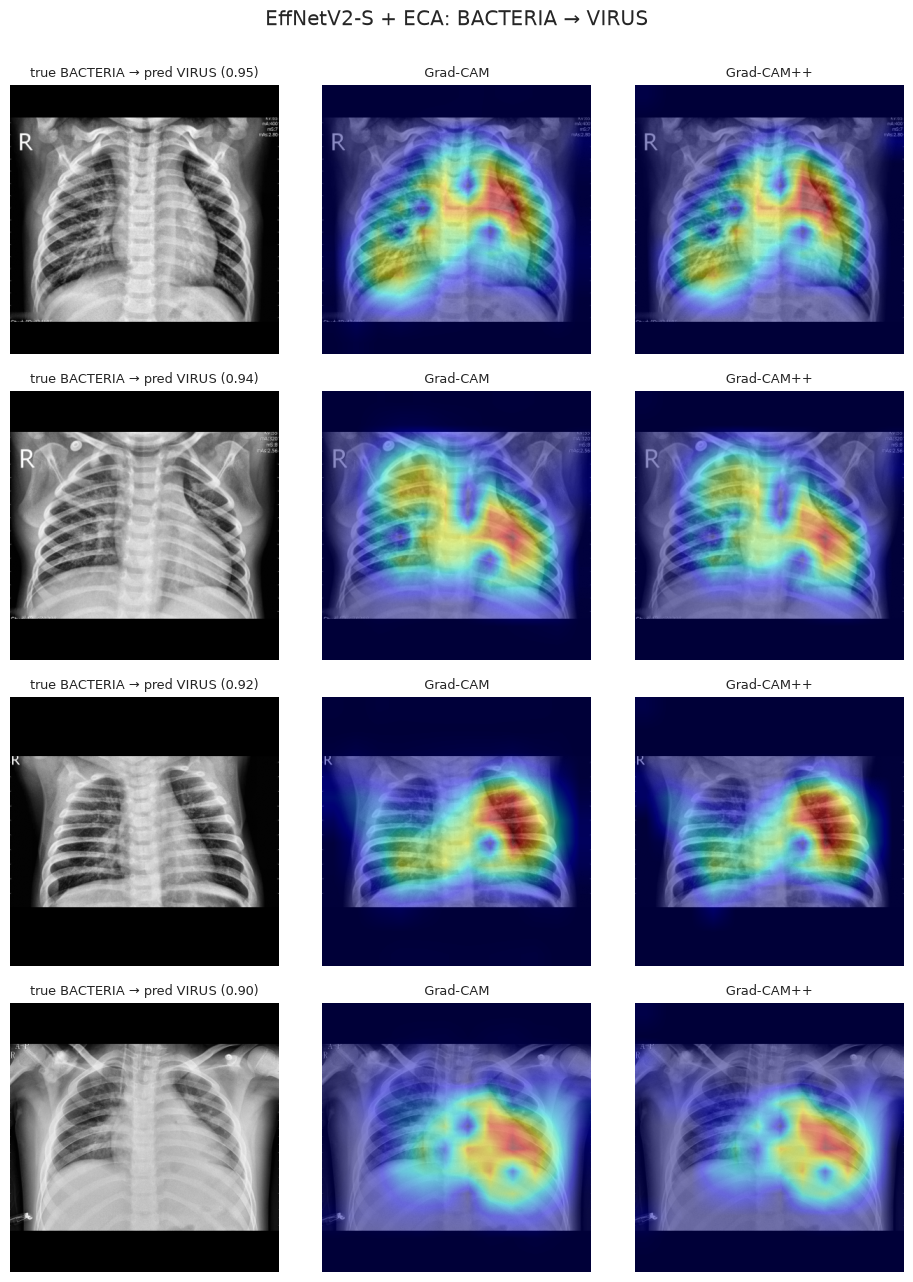

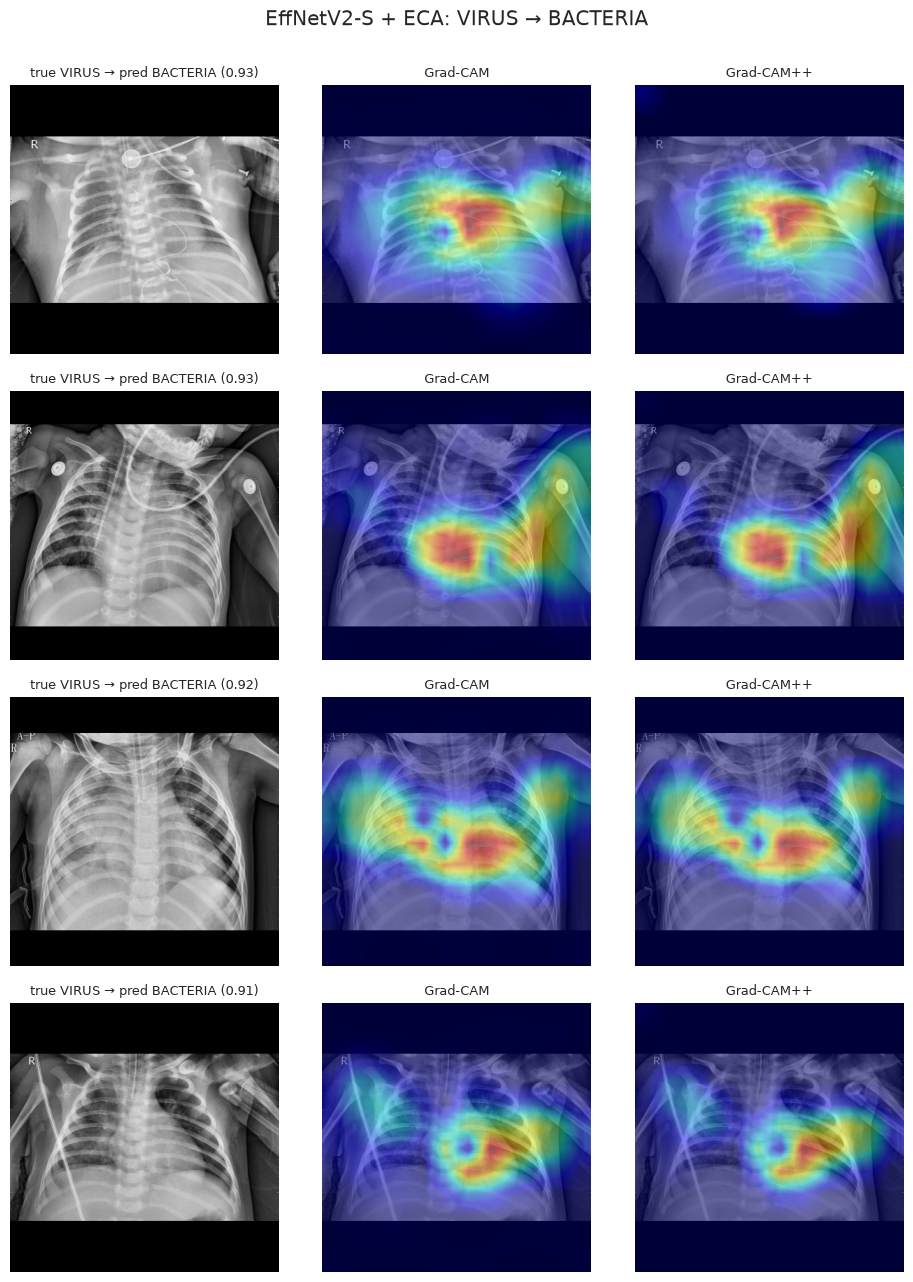

In [9]:
# ============================================================
# Qualitative: misclassified — BACTERIA→VIRUS and VIRUS→BACTERIA (most confident errors of the last model)
# ============================================================
def error_figure(true_c, pred_c, fname, k=4):
    idx = np.where((labels == true_c) & (CAMS[main]["pred"] == pred_c))[0]
    idx = idx[np.argsort(-CAMS[main]["probs"][idx, pred_c])][:k]
    if len(idx) == 0:
        print("No such errors"); return
    fig, axes = plt.subplots(len(idx), 3, figsize=(9.6, 3.2 * len(idx)), squeeze=False)
    for r, i in enumerate(idx):
        cf = CAMS[main]["probs"][i, pred_c]
        show(axes[r, 0], i, None, f"true {CLASSES[true_c]} → pred {CLASSES[pred_c]} ({cf:.2f})")
        show(axes[r, 1], i, CAMS[main]["gradcam"][i], "Grad-CAM")
        show(axes[r, 2], i, CAMS[main]["gradcampp"][i], "Grad-CAM++")
    plt.suptitle(f"{main}: {CLASSES[true_c]} → {CLASSES[pred_c]}", y=1.0)
    plt.tight_layout(); plt.savefig(FIG_DIR / fname, dpi=300, bbox_inches="tight"); plt.show()

error_figure(1, 2, "xai_errors_bacteria_to_virus.png")
error_figure(2, 1, "xai_errors_virus_to_bacteria.png")

In [10]:
# ============================================================
# Save a compact summary
# ============================================================
summary = {"fold": FOLD, "seed": SEED, "target_layer": TARGET_LAYER, "steps": STEPS, "n_test": int(N),
           "n_sanity": int(len(sidx)), "n_eval": int(len(eval_idx))}
(XAI_DIR / "xai_config.json").write_text(json.dumps(summary, indent=2))
print("Saved to", XAI_DIR, "and", FIG_DIR)

Saved to /mnt/g/Research paper/Research paper/Pneumonia-MultiModel-XAI/results/xai and /mnt/g/Research paper/Research paper/Pneumonia-MultiModel-XAI/results/figures


In [1]:
import numpy as np
for k, v in list(globals().items()):
    if not k.startswith('_') and isinstance(v, (dict, np.ndarray)) and any(s in k.lower() for s in ['del', 'ins', 'score', 'auc']):
        print(k, type(v).__name__, getattr(v, 'shape', list(v.keys())[:5]))

In [2]:
import numpy as np, pandas as pd
for k, v in list(globals().items()):
    if k.startswith('_'): continue
    if isinstance(v, (dict, list, np.ndarray, pd.DataFrame)):
        s = v.shape if hasattr(v, 'shape') else (len(v), list(v.keys())[:4] if isinstance(v, dict) else '')
        print(k, type(v).__name__, s)

In list (3, '')
Out dict (0, [])
